# Ajustement de la courbe de polarisation de la pile Toyota Mirai II sur les cycles mesurés

Ce notebook ajuste un modèle de polarisation sur les cycles de roulage enregistrés sur la Toyota Mirai II. Il contient uniquement l'ajustement, sans vieillissement.

**Modèle (tension d'une cellule) :**

$$V(j)=E_{\mathrm{rev}}(T)-\frac{RT}{\alpha_cF}\ln\frac{j}{i_{0,c}}-j\,R_{\mathrm{tot}}+B_c\ln\left(1-\frac{j}{i_{\lim}}\right),\qquad E_{\mathrm{rev}}(T)=1{,}229-0{,}85\cdot10^{-3}(T-298{,}15)$$

**Paramètres fixés :** $T=343{,}15$ K, $\alpha_c=1$, $N_{\mathrm{cell}}=330$, $A=297$ cm².

**Paramètres ajustés :** $i_{0,c}$, $R_{\mathrm{tot}}$, $B_c$, $i_{\lim}$.

## 0. Fichiers d'entrée

Cette cellule prépare les fichiers de mesures dont le notebook a besoin, dans le dossier du notebook. Il n'y a rien à faire : exécutez-la simplement.

- Si un fichier est déjà là, il est gardé.
- Sinon, il est pris dans le dossier `data/` du dépôt (si le notebook est dans `h2-ageing-lca/notebooks/`), ou téléchargé depuis le dépôt GitHub public (connexion internet nécessaire).

In [ ]:
BESOINS = ['signaux_fuel_cell_1.xlsx']

import json, shutil, urllib.request
from pathlib import Path
import pandas as pd

DEPOT_EN_LIGNE = "https://raw.githubusercontent.com/Ayabh12/h2-ageing-lca/main/"
ICI = Path.cwd()

def source(chemin):
    """Chemin local dans le dépôt si disponible, sinon adresse sur GitHub."""
    for base in (ICI.parent, ICI.parent / "h2-ageing-lca", ICI / "h2-ageing-lca"):
        if (base / chemin).exists():
            return str(base / chemin)
    return DEPOT_EN_LIGNE + chemin

def copier(chemin, nom):
    src = source(chemin)
    if src.startswith(("http://", "https://", "file:")):
        urllib.request.urlretrieve(src, ICI / nom)
    else:
        shutil.copy(src, ICI / nom)

def preparer(nom, fabrication):
    if (ICI / nom).exists():
        print(f"déjà présent : {nom}")
    else:
        fabrication()
        print(f"préparé      : {nom}")

def _signaux():
    sig = pd.read_csv(source("data/measurements/mirai2_fuel_cell_signals.csv"))
    sig.columns = ["Temps (s)", "Vitesse (km/h)", "Courant FC (A)", "Tension FC (V)", "Niveau hydrogène restant (%)"]
    sig.to_excel(ICI / "signaux_fuel_cell_1.xlsx", index=False)

def _trajet():
    trip = pd.read_csv(source("data/measurements/mirai2_fuel_cell_trip.csv"))
    trip.columns = ["Temps (s)", "Courant FC (A)", "Tension FC (V)"]
    trip.to_excel(ICI / "mirai2_fuel_cell_trip.xlsx", sheet_name="wltp", index=False)

FICHIERS = {
    "signaux_fuel_cell_1.xlsx": _signaux,
    "mirai2_fuel_cell_trip.xlsx": _trajet,
    "profil_electrolyseur_ACV_duree_vie (2).xlsx": lambda: copier("data/measurements/nel_mc250_wind_profile.xlsx", "profil_electrolyseur_ACV_duree_vie (2).xlsx"),
    "pemwe_parametres.json": lambda: copier("data/parameters/pemwe_fit.json", "pemwe_parametres.json"),
    "medium.xlsx": lambda: copier("notebooks/medium.xlsx", "medium.xlsx"),
    "nuc.xlsx": lambda: copier("notebooks/nuc.xlsx", "nuc.xlsx"),
    "wind.xlsx": lambda: copier("notebooks/wind.xlsx", "wind.xlsx"),
    "pv.xlsx": lambda: copier("notebooks/pv.xlsx", "pv.xlsx"),
}
for nom in BESOINS:
    preparer(nom, FICHIERS[nom])

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

plt.rcParams.update({"figure.dpi":120,"font.size":10.5,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
R=8.314462618; F=96485.33212
T_K=343.15; ALPHA_C=1.0; N_CELL=330; A_GEO=297.0
E_REV=1.229-0.85e-3*(T_K-298.15)
OUT=Path("resultats_fitting_PEMFC"); OUT.mkdir(exist_ok=True)
print(f"E_rev(T) = {E_REV:.4f} V")

E_rev(T) = 1.1908 V


## 1. Données et découpage en cycles

Le fichier `signaux_fuel_cell 1.xlsx` regroupe les enregistrements les uns à la suite des autres. Le temps repart de zéro au début de chaque enregistrement, ce qui permet de les séparer. Un enregistrement est classé « roulage » si la vitesse du véhicule y dépasse zéro, et « arrêt » sinon.

In [2]:
CHEMIN = Path("signaux_fuel_cell_1.xlsx")
cands = [CHEMIN, Path.cwd()/"signaux_fuel_cell 1.xlsx", Path.cwd()/"signaux_fuel_cell_1.xlsx"]
fichier = next((x for x in cands if x.exists()), None)
if fichier is None: raise FileNotFoundError("Indiquez le chemin du fichier dans CHEMIN.")

sig = pd.read_excel(fichier).rename(columns={"Temps (s)":"t","Vitesse (km/h)":"v","Courant FC (A)":"I",
                                             "Tension FC (V)":"U","Niveau hydrogène restant (%)":"H2"})
sig["enr"] = np.r_[0, np.cumsum(np.diff(sig.t.to_numpy()) < 0)]
info = sig.groupby("enr").agg(duree_s=("t","max"), v_max=("v","max"), I_max=("I","max"),
                              H2_debut=("H2","first"), H2_fin=("H2","last"))
info["type"] = np.where(info.v_max > 0, "roulage", "arrêt")
ROULAGE = info.index[info.type == "roulage"].tolist()
print(f"{len(sig)} points, {len(info)} enregistrements : {len(ROULAGE)} de roulage, {(info.type=='arrêt').sum()} à l'arrêt")
display(info.round(1))

67761 points, 25 enregistrements : 12 de roulage, 13 à l'arrêt


,duree_s,v_max,I_max,H2_debut,H2_fin,type
enr,,,,,,
0,330.0,0.0,24.4,56.5,56.0,arrêt
1,2031.9,107.3,421.2,56.0,52.5,roulage
2,872.0,87.1,391.8,50.0,48.5,roulage
3,3650.9,0.0,25.0,45.5,45.0,arrêt
4,1482.0,111.7,599.8,79.0,75.5,roulage
5,1500.0,0.0,24.4,75.0,75.0,arrêt
6,164.0,32.1,104.0,68.5,68.0,roulage
7,2541.9,0.0,25.2,63.0,62.5,arrêt
8,5541.9,119.9,600.4,62.0,38.5,roulage


**Remarque.** Le découpage donne 25 enregistrements. Le n° 0 (330 s à l'arrêt) se termine avec un niveau d'hydrogène de 56,0 %, et le n° 1 (WLTP) commence au même niveau. Ce sont donc probablement deux parties du même essai, ce qui fait 24 cycles, comme l'indique l'auteur des mesures. Seuls les cycles de roulage servent à l'ajustement : ce regroupement ne change rien au résultat.

## 2. Sélection des points

1. **Cycles de roulage uniquement.**
2. **$I\ge30$ A.** En dessous de 25 A, la tension mesurée reste presque constante vers 289 V, quel que soit le courant (vérifié dans la cellule suivante). Le modèle électrochimique ne décrit pas ce palier, donc ces points sont exclus.
3. **Points quasi stationnaires :** $|I(t)-I(t-1)|/I(t)<10\,\%$. Ce filtre écarte les variations rapides de courant.
4. **Médianes par classe.** Les points retenus sont regroupés en 18 classes de courant, espacées logarithmiquement entre 30 et 610 A. Chaque classe est résumée par la médiane de $I$ et de $U$. Une classe n'est gardée que si elle contient au moins 5 points provenant d'au moins 2 cycles.

In [3]:
I_MIN = 30.0; TOL = 0.10
roul = sig[sig.enr.isin(ROULAGE)].copy()

def stable(g, tol=TOL):
    I = g.I.to_numpy(); ok = np.zeros(len(I), bool)
    ok[1:] = np.abs(I[1:]-I[:-1])/np.maximum(I[1:], 1.0) < tol
    return pd.Series(ok, index=g.index)

roul["stable"] = roul.groupby("enr", group_keys=False).apply(stable)
pts = roul[(roul.I >= I_MIN) & roul.stable]

BORNES = np.unique(np.round(np.geomspace(I_MIN, 610, 19)))
def courbe_mediane(p):
    g = p.groupby(pd.cut(p.I, BORNES), observed=True).agg(
        I=("I","median"), U=("U","median"), q25=("U", lambda x: x.quantile(.25)),
        q75=("U", lambda x: x.quantile(.75)), n=("U","size"), n_cycles=("enr","nunique"))
    return g[(g.n >= 5) & (g.n_cycles >= 2)].reset_index(drop=True)

POL = courbe_mediane(pts)
bas = roul[(roul.I > 0.5) & (roul.I < 25)]
print(f"Palier à faible courant (0,5–25 A) : U médiane = {bas.U.median():.1f} V ({bas.U.median()/N_CELL:.3f} V/cellule)")
print(f"Points I ≥ {I_MIN:.0f} A : {(roul.I >= I_MIN).sum()} ; quasi stationnaires : {len(pts)} ; classes retenues : {len(POL)}")
display(POL.round(2))

Palier à faible courant (0,5–25 A) : U médiane = 289.1 V (0.876 V/cellule)
Points I ≥ 30 A : 16190 ; quasi stationnaires : 8349 ; classes retenues : 18


,I,U,q25,q75,n,n_cycles
0,33.2,282.25,281.30,283.40,326,11
1,38.4,280.80,279.80,281.80,1211,12
2,45.6,278.10,276.90,279.60,719,12
3,54.4,275.20,274.00,276.50,530,12
4,64.0,272.90,271.90,274.00,550,12
5,76.2,270.20,269.30,271.50,857,11
6,89.4,267.50,266.50,268.60,1087,11
7,105.8,264.50,263.30,266.10,911,11
8,122.8,261.60,260.20,263.40,745,11
9,146.6,259.10,257.60,260.70,421,11


## 3. Ajustement

Les quatre paramètres sont ajustés par moindres carrés bornés sur les médianes, en tension par cellule. Pour éviter un minimum local, l'ajustement est lancé depuis 200 points de départ tirés au hasard (multistart), et on garde le meilleur résultat. La cellule vérifie que les départs convergent tous vers le même minimum.

Bornes : $\log_{10} i_{0,c}\in[-12,-1]$, $R_{\mathrm{tot}}\in[0;0{,}3]$ Ω cm², $B_c\in[0;0{,}3]$ V, $i_{\lim}\in[2{,}03;6]$ A cm⁻². La borne basse de $i_{\lim}$ est placée juste au-dessus du courant maximal mesuré (601,8 A, soit 2,026 A cm⁻²), pour que le logarithme reste défini sur tous les points.

In [4]:
LO = np.array([-12, 0, 0, 2.03]); HI = np.array([-1, .3, .3, 6])
def V(j, th):
    l, Rt, Bc, il = th
    return E_REV - R*T_K/(ALPHA_C*F)*np.log(j/10**l) - j*Rt + Bc*np.log(1 - j/il)

def ajuster(P, n_init=200, seed=1, garder_tout=False):
    rng = np.random.default_rng(seed); jj = P.I.to_numpy()/A_GEO; vv = P.U.to_numpy()/N_CELL; best = None; tous = []
    for _ in range(n_init):
        s = least_squares(lambda x: V(jj, x) - vv, rng.uniform(LO, HI), bounds=(LO, HI), max_nfev=5000)
        tous.append(np.r_[s.cost, s.x])
        if best is None or s.cost < best.cost: best = s
    return (best, np.array(tous)) if garder_tout else best

best, DEPARTS = ajuster(POL, garder_tout=True); TH = best.x
# Contrôle du multistart : nombre de départs qui atteignent le même minimum (coût à 0,1 % près)
au_min = DEPARTS[:, 0] <= best.cost*1.001
print(f"Multistart : {au_min.sum()}/{len(DEPARTS)} départs convergent vers le même minimum ; "
      f"i_lim parmi eux : {DEPARTS[au_min, 4].min():.3f} – {DEPARTS[au_min, 4].max():.3f} A/cm2")
e = best.fun; vv = POL.U.to_numpy()/N_CELL
RMSE = np.sqrt(np.mean(e**2)); MAE = np.mean(np.abs(e)); R2 = 1 - np.sum(e**2)/np.sum((vv - vv.mean())**2)
print(f"i0,c = {10**TH[0]:.3e} A/cm2 ; R_tot = {1e3*TH[1]:.1f} mOhm.cm2 ; B_c = {TH[2]:.4f} V ; i_lim = {TH[3]:.3f} A/cm2")
print(f"RMSE = {1e3*RMSE:.2f} mV/cellule ({N_CELL*RMSE:.2f} V stack) ; MAE = {1e3*MAE:.2f} mV/cellule ; R2 = {R2:.4f}")

Multistart : 200/200 départs convergent vers le même minimum ; i_lim parmi eux : 2.302 – 2.303 A/cm2
i0,c = 1.525e-06 A/cm2 ; R_tot = 46.2 mOhm.cm2 ; B_c = 0.0265 V ; i_lim = 2.302 A/cm2
RMSE = 1.99 mV/cellule (0.66 V stack) ; MAE = 1.71 mV/cellule ; R2 = 0.9989


## 4. Incertitude : bootstrap par cycles

Les points d'un même cycle ne sont pas indépendants, c'est donc le cycle qui sert d'unité de tirage. On tire 12 cycles avec remise parmi les 12 cycles de roulage, on recalcule les médianes, puis on refait l'ajustement. L'opération est répétée 500 fois. L'intervalle à 95 % est donné par les percentiles 2,5 et 97,5 %.

La corrélation entre paramètres est calculée à partir du jacobien à l'optimum.

In [5]:
rng = np.random.default_rng(42); BOOT = []
for k in range(500):
    tirage = rng.choice(ROULAGE, len(ROULAGE))
    Pb = courbe_mediane(pd.concat([pts[pts.enr == c] for c in tirage]))
    if len(Pb) >= 6: BOOT.append(ajuster(Pb, n_init=8, seed=k).x)
BOOT = np.array(BOOT); q = np.percentile(BOOT, [2.5, 97.5], axis=0)

J = best.jac; cov = np.linalg.inv(J.T@J)*np.sum(e**2)/(len(e) - 4); sd = np.sqrt(np.diag(cov))
noms = ["log10 i0,c", "R_tot", "B_c", "i_lim"]
print(f"{len(BOOT)} rééchantillonnages valides")
print("Matrice de corrélation des paramètres :")
display(pd.DataFrame(cov/np.outer(sd, sd), index=noms, columns=noms).round(3))

500 rééchantillonnages valides
Matrice de corrélation des paramètres :


,"log10 i0,c",R_tot,B_c,i_lim
"log10 i0,c",1.000,0.753,-0.689,-0.629
R_tot,0.753,1.000,-0.992,-0.968
B_c,-0.689,-0.992,1.000,0.991
i_lim,-0.629,-0.968,0.991,1.000


## 5. Validation croisée par cycle

Chaque cycle est retiré à son tour : on réajuste le modèle sur les autres cycles, puis on calcule l'erreur sur les points quasi stationnaires du cycle retiré. Les cycles qui ont moins de 20 points sont exclus de ce test.

In [6]:
lig = []
for c in ROULAGE:
    test = pts[pts.enr == c]
    if len(test) < 20: continue
    th = ajuster(courbe_mediane(pts[pts.enr != c]), n_init=30).x
    err = N_CELL*V(test.I.to_numpy()/A_GEO, th) - test.U.to_numpy()
    lig.append({"Cycle": c, "Points": len(test), "RMSE (V stack)": np.sqrt(np.mean(err**2)), "Biais médian (V stack)": np.median(err)})
VALID = pd.DataFrame(lig).set_index("Cycle")
display(VALID.round(2))
print(f"Moyenne : RMSE = {VALID['RMSE (V stack)'].mean():.2f} V ; biais de {VALID['Biais médian (V stack)'].min():.2f} à {VALID['Biais médian (V stack)'].max():.2f} V")

Moyenne : RMSE = 2.03 V ; biais de -1.64 à 0.60 V


,Points,RMSE (V stack),Biais médian (V stack)
Cycle,,,
1,230,2.03,-0.05
2,59,2.59,-1.64
4,287,1.95,-0.56
8,2457,1.90,0.50
9,218,1.91,-0.90
10,1030,1.96,0.00
11,764,2.48,-0.61
14,1820,1.87,0.60
15,544,2.05,0.50


## 6. Résultats

<cellule 8>:4: RuntimeWarning: invalid value encountered in log


,Paramètre,Valeur,IC95 bas,IC95 haut,Unité,Statut
0,E_rev(T),1.191,NaN,NaN,V,fixé
1,alpha_c,1,NaN,NaN,-,fixé
2,"i0,c",1.525e-06,1.467e-06,1.609e-06,A/cm2,ajusté
3,R_tot,46.23,14.22,62.23,mOhm.cm2,ajusté
4,B_c,0.02646,5.207e-09,0.1325,V,ajusté
5,i_lim,2.302,2.03,6,A/cm2,ajusté
6,N_cell,330,NaN,NaN,-,fixé
7,A,297,NaN,NaN,cm2,fixé
8,RMSE,1.986,NaN,NaN,mV/cellule,
9,MAE,1.713,NaN,NaN,mV/cellule,


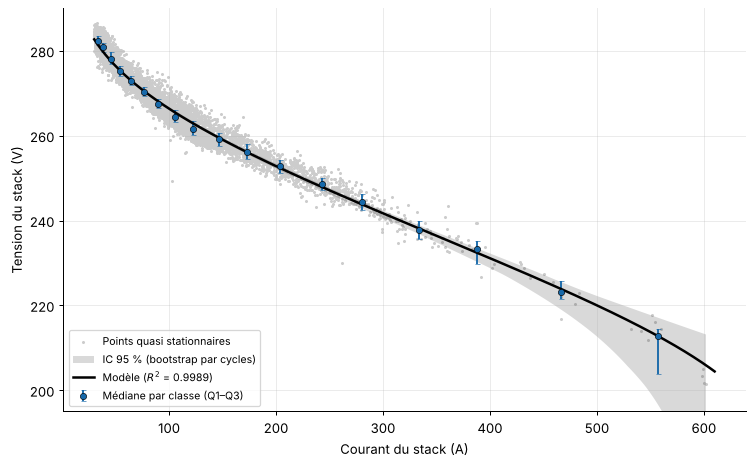

In [7]:
pd.set_option("display.float_format", "{:.4g}".format)
RES = pd.DataFrame({
 "Paramètre": ["E_rev(T)", "alpha_c", "i0,c", "R_tot", "B_c", "i_lim", "N_cell", "A", "RMSE", "MAE", "R2"],
 "Valeur": [E_REV, ALPHA_C, 10**TH[0], 1e3*TH[1], TH[2], TH[3], N_CELL, A_GEO, 1e3*RMSE, 1e3*MAE, R2],
 "IC95 bas": [np.nan, np.nan, 10**q[0,0], 1e3*q[0,1], q[0,2], q[0,3], np.nan, np.nan, np.nan, np.nan, np.nan],
 "IC95 haut": [np.nan, np.nan, 10**q[1,0], 1e3*q[1,1], q[1,2], q[1,3], np.nan, np.nan, np.nan, np.nan, np.nan],
 "Unité": ["V", "-", "A/cm2", "mOhm.cm2", "V", "A/cm2", "-", "cm2", "mV/cellule", "mV/cellule", "-"],
 "Statut": ["fixé", "fixé", "ajusté", "ajusté", "ajusté", "ajusté", "fixé", "fixé", "", "", ""]})
display(RES)
RES.to_csv(OUT/"parametres_fitting.csv", index=False, encoding="utf-8-sig")
POL.to_csv(OUT/"courbe_mediane.csv", index=False, encoding="utf-8-sig")

Ig = np.linspace(I_MIN, 610, 500)
bande = np.array([N_CELL*V(Ig/A_GEO, th) for th in BOOT]); b_lo, b_hi = np.percentile(bande, [2.5, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(8.5, 5.3))
ax.scatter(pts.I, pts.U, s=2, color="0.8", rasterized=True, label="Points quasi stationnaires")
ax.errorbar(POL.I, POL.U, yerr=[POL.U - POL.q25, POL.q75 - POL.U], fmt="o", ms=5, color="#1769AA",
            mec="black", mew=.5, capsize=2, label="Médiane par classe (Q1–Q3)")
ax.fill_between(Ig, b_lo, b_hi, color="black", alpha=.15, lw=0, label="IC 95 % (bootstrap par cycles)")
ax.plot(Ig, N_CELL*V(Ig/A_GEO, TH), "k", lw=2, label=f"Modèle ($R^2$ = {R2:.4f})")
ax.set(xlabel="Courant du stack (A)", ylabel="Tension du stack (V)", ylim=(195, 290))
ax.legend(fontsize=8.5, loc="lower left"); fig.tight_layout(); fig.savefig(OUT/"fitting_polarisation.png", dpi=220); plt.show()

## 7. Lecture des résultats et hypothèses

**Ce que l'ajustement détermine bien**
- $i_{0,c}$ : son intervalle de confiance est étroit.
- La courbe de tension sur la plage mesurée : la bande de confiance reste étroite jusqu'à environ 400 A.

**Ce qu'il ne détermine pas**
- $R_{\mathrm{tot}}$, $B_c$ et $i_{\lim}$ sont fortement corrélés (matrice de la section 4). Plusieurs combinaisons reproduisent les données aussi bien, d'où leurs intervalles larges : les données ne permettent pas de les séparer. Leurs valeurs individuelles ne doivent pas être interprétées physiquement.
- Au-delà de 400 A, il y a peu de points quasi stationnaires, et la bande de confiance s'élargit.

**Hypothèses**
1. Température constante de 70 °C (343,15 K), non mesurée.
2. $E_{\mathrm{rev}}$ sans terme de pression (pas de terme de Nernst) : $i_{0,c}$ est donc un paramètre effectif.
3. $\alpha_c=1$. La perte anodique est négligée, car l'oxydation de l'hydrogène sur platine est très rapide (Durst et al., 2014). Sa faible contribution, presque proportionnelle au courant (Gerling et al., 2022), est incluse dans $R_{\mathrm{tot}}$, qui est donc une résistance apparente.
4. 330 cellules identiques ; surface active de 297 cm², valeur supposée (non publiée par Toyota).
5. Les points de faible courant (< 30 A) et les variations rapides de courant sont exclus ; le modèle n'est valable qu'entre 30 et 610 A.
6. L'état de la pile est celui des mesures (pile déjà utilisée, sans vieillissement entre les cycles).